# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Выполнен вариант NLP, обязательные разделы 1–5 и бонусы 6.3 и 6.5. Устройство определяется в выводе ячейки настройки; измерения относятся к этому устройству.

Модель: [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), MIT; датасет: [Babelscape/WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), русский язык, CC BY-NC-SA 4.0. Для доступного локального бюджета используются 8000 / 2000 / 2000 предложений из исходных train_ru / val_ru / test_ru, выборка с seed=0. Это ограничение эксперимента, а не полный корпус.

Источники: исходный шаблон задания; карточки модели и датасета; [статья WikiNEuRal](https://aclanthology.org/2021.findings-emnlp.215/); документация [token classification](https://huggingface.co/docs/transformers/tasks/token_classification), [Trainer](https://huggingface.co/docs/transformers/main_classes/trainer), [seqeval](https://github.com/chakki-works/seqeval). При подготовке решения использован Codex. Бонусы 6.1, 6.2 и 6.4 не выполнялись.

**Результат прогона:** Ноутбук выполнен целиком с FAST_MODE=False на локальном Mac, Apple GPU (MPS), float32. Версии: torch 2.15.0, transformers 5.22.1, datasets 5.1.0. Основное обучение заняло 86.2 с. Все обязательные разделы выполнены; бонусы 6.3 и 6.5 выполнены.

In [1]:
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    Trainer,
    TrainingArguments,
)

transformers.logging.set_verbosity_error()
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 11

print(
    f"torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}"
)
print(f"CUDA available: {torch.cuda.is_available()}")

/Users/vlyrdv/Desktop/dl2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1110 12:54:29.313000 76059 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == "cuda" else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False
BONUS_TASKS = {
    "6.3",
    "6.5",
}
assert BONUS_TASKS <= {
    "6.1",
    "6.2",
    "6.3",
    "6.4",
    "6.5",
}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None
N_EVAL = 500 if FAST_MODE else None
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = "cointegrated/rubert-tiny2"
REVISION = "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae"
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, "укажите MODEL_ID"
assert re.fullmatch(
    r"[0-9a-f]{40}", REVISION or ""
), "REVISION - полный commit hash из 40 символов, а не main и не тег"
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {
    s.rfilename: f"{s.size / 2**20:.0f} MB"
    for s in info.siblings
    if s.rfilename.endswith(
        (
            ".safetensors",
            ".bin",
        )
    )
}
print(
    f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}'
)
print(f"updated:  {info.last_modified}\nweights:  {weights}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, "нужен fast-токенизатор: word_ids() есть только у него"
print(type(tokenizer).__name__, "vocab size", tokenizer.vocab_size)
print(tokenizer.tokenize("Петр Ильич Чайковский родился в Воткинске"))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** rubert-tiny2 — базовый русскоязычный BERT-энкодер с лицензией MIT, без готовой NER-головы. В карточке описаны дистилляция представлений LaBSE и расширение словаря до 83828 токенов; малый hidden size и три слоя позволяют обучать модель локально. По сравнению с DeepPavlov/rubert-base-cased (около 180 млн параметров) и xlm-roberta-base (около 280 млн) ожидаю меньшие затраты памяти и времени, но меньшую выразительность; XLM-R дополнительно поддерживает много языков. Карточки не дают сопоставимого NER-эксперимента на выбранной выборке, поэтому превосходство по качеству не утверждаю. Полный commit hash фиксирует веса, конфигурацию и токенизатор: без него обновление main могло бы изменить сегментацию слов и результаты.

Источники: [rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), [RuBERT](https://huggingface.co/DeepPavlov/rubert-base-cased), [XLM-R](https://huggingface.co/FacebookAI/xlm-roberta-base).

**Результат прогона:** У модели с NER-головой на 9 тегов 29,098,929 параметров. Размер трех слоев энкодера вместе — 2,301,552; это объясняет возможность локального обучения.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS
)
cfg = demo_model.config
print(
    {
        k: getattr(cfg, k, None)
        for k in [
            "model_type",
            "vocab_size",
            "hidden_size",
            "num_hidden_layers",
            "num_attention_heads",
            "intermediate_size",
            "max_position_embeddings",
        ]
    }
)
for name, module in demo_model.named_children():
    print(f"{name:<12} {type(module).__name__}")

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    base = model.base_model
    embeddings = base.embeddings
    encoder = getattr(base, "encoder", None)
    layers = getattr(encoder, "layer", None)
    if layers is None:
        layers = getattr(base, "transformer", None)
        layers = getattr(layers, "layer", None)
    if layers is None:
        raise ValueError("Не найдены слои энкодера")

    embedding_ids = {
        id(p) for p in embeddings.parameters()
    }
    layer_ids = {
        id(p) for layer in layers for p in layer.parameters()
    }
    base_ids = {
        id(p) for p in base.parameters()
    }
    blocks = {
        "embeddings": 0,
        "encoder": 0,
        "head": 0,
        "other": 0,
        "layers": [
            sum(p.numel() for p in layer.parameters()) for layer in layers
        ],
    }
    for parameter in model.parameters():
        key = "other"
        if id(parameter) in embedding_ids:
            key = "embeddings"
        elif id(parameter) in layer_ids:
            key = "encoder"
        elif id(parameter) not in base_ids:
            key = "head"
        blocks[key] += parameter.numel()
    return blocks

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert (
    sum(
        blocks[k]
        for k in [
            "embeddings",
            "encoder",
            "head",
            "other",
        ]
    )
    == total
)
assert blocks["head"] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert (
    len(blocks["layers"]) == cfg.num_hidden_layers
    and sum(blocks["layers"]) == blocks["encoder"]
), "encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other"
assert blocks["embeddings"] >= cfg.vocab_size * cfg.hidden_size
for k in [
    "embeddings",
    "encoder",
    "head",
    "other",
]:
    print(f"{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}")
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [
    [
        "Петр",
        "Чайковский",
        "родился",
        "в",
        "Воткинске",
        ".",
    ],
    [
        "ITMO",
        "University",
        "is",
        "in",
        "Saint",
        "Petersburg",
    ],
]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors="pt")
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
print("input_ids:", tuple(enc["input_ids"].shape))
print("attention_mask:", tuple(enc["attention_mask"].shape))
print("hidden_states:", [
    tuple(state.shape) for state in out.hidden_states
])
print("logits:", tuple(out.logits.shape))

input_ids: (2, 11)
attention_mask: (2, 11)
hidden_states: [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits: (2, 11, 7)


In [11]:
B, T = enc["input_ids"].shape
assert B == 2 and out.logits.shape == (
    B,
    T,
    N_DEMO_LABELS,
)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(
    h.shape
    == (
        B,
        T,
        cfg.hidden_size,
    )
    for h in out.hidden_states
)


x = {
    k: v.to(device)
    for k, v in tokenizer(
        [
            [
                "слово",
            ]
            * 62,
        ]
        * 32,
        is_split_into_words=True,
        return_tensors="pt",
    ).items()
}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == "cuda":
        torch.cuda.synchronize()
print(
    f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}'
)
demo_model = demo_model.cpu()

forward 32 x 64: 16.3 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Входные input_ids и attention_mask имеют форму (B, T), эмбеддинги и каждый слой энкодера — (B, T, H), а линейная голова — (B, T, K). Конкретные формы и число параметров приведены в выводах выше. Основная память у tiny-модели приходится на таблицу эмбеддингов: словарь большой, а энкодер узкий и содержит только три слоя. Между токенами информация передается в слоях энкодера; lookup эмбеддингов и классификатор работают с каждой позицией отдельно. T включает сабворды, специальные токены и padding, поэтому может превышать число слов.

**Результат прогона:** B=2, T=11, H=312; input_ids и mask имеют форму (2, 11), hidden_states — (2, 11, 312), demo-logits — (2, 11, 7). Эмбеддинги содержат 26,794,560 параметров (92.1%), энкодер — 2,301,552, demo-голова — 2,191, other — 0.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
print("Используется WikiNEuRal ru; пример контракта будет показан после загрузки.")

Используется WikiNEuRal ru; пример контракта будет показан после загрузки.


In [13]:
DATASET_ID = "Babelscape/wikineural"
DATASET_CONFIG = None
DATASET_REVISION = "74c9b9dca034bb1606a6769457983904bd976803"
SOURCE_SPLITS = {
    "train": "train_ru",
    "validation": "val_ru",
    "test": "test_ru",
}
SPLIT_LIMITS = {
    "train": 8000,
    "validation": 2000,
    "test": 2000,
}
raw = DatasetDict()
source_sizes = {}
for split, source_split in SOURCE_SPLITS.items():
    source = load_dataset(
        DATASET_ID,
        split=source_split,
        revision=DATASET_REVISION,
    )
    source_sizes[split] = len(source)
    raw[split] = (
        source.shuffle(seed=SEED)
        .select(range(min(SPLIT_LIMITS[split], len(source))))
        .select_columns(
            [
                "tokens",
                "ner_tags",
            ]
        )
    )
LABEL_NAMES = [
    "O",
    "B-PER",
    "I-PER",
    "B-ORG",
    "I-ORG",
    "B-LOC",
    "I-LOC",
    "B-MISC",
    "I-MISC",
]
print("Исходные размеры:", source_sizes)
print(raw)
print(list(zip(raw["train"][0]["tokens"], raw["train"][0]["ner_tags"])))

Исходные размеры: {'train': 92320, 'validation': 11540, 'test': 11580}
DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
})
[('Работы', 0), ('по', 0), ('строительству', 0), ('первоначальной', 0), ('инфраструктуры', 0), ('аэропорта', 0), ('начались', 0), ('в', 0), ('1937', 0), ('году', 0), ('на', 0), ('месте', 0), ('девяти', 0), ('сельскохозяйственных', 0), ('угодий', 0), (',', 0), ('выкупленных', 0), ('муниципальным', 0), ('комитетом', 0), ('Торонто', 5), ('у', 0), ('частных', 0), ('владельцев', 0), ('.', 0)]


train {"sentences": 8000, "entities": {"LOC": 5967, "MISC": 2088, "ORG": 1743, "PER": 2838}, "sentence_lengths": {"count": 8000, "mean": 19.461875, "median": 17.0, "p95": 39.0, "max": 135}, "span_lengths": {"count": 12636, "mean": 1.293684710351377, "median": 1.0, "p95": 3.0, "max": 17}, "span_length_histogram": {"1": 10073, "2": 1793, "3": 556, "4": 136, "5": 35, "6": 25, "7": 8, "8": 4, "9": 4, "10": 1, "17": 1}, "lengths_by_type": {"LOC": {"count": 5967, "mean": 1.1213340036869448, "median": 1.0, "p95": 2.0, "max": 7}, "MISC": {"count": 2088, "mean": 1.4506704980842913, "median": 1.0, "p95": 3.0, "max": 9}, "ORG": {"count": 1743, "mean": 1.6144578313253013, "median": 1.0, "p95": 3.0, "max": 17}, "PER": {"count": 2838, "mean": 1.3435517970401691, "median": 1.0, "p95": 2.0, "max": 5}}}
validation {"sentences": 2000, "entities": {"LOC": 1525, "MISC": 461, "ORG": 464, "PER": 741}, "sentence_lengths": {"count": 2000, "mean": 18.749, "median": 17.0, "p95": 38.0, "max": 107}, "span_lengths

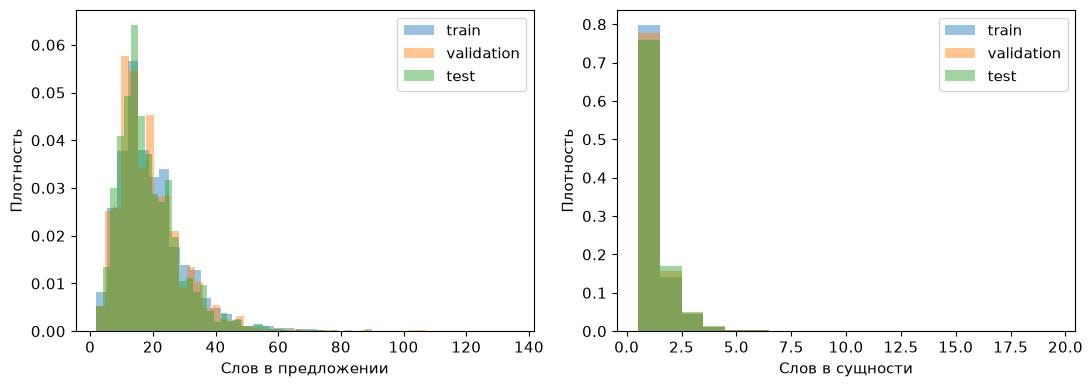

In [14]:
def describe_lengths(values):
    values = np.asarray(values)
    return {
        "count": int(len(values)),
        "mean": float(values.mean()) if len(values) else 0.0,
        "median": float(np.median(values)) if len(values) else 0.0,
        "p95": float(np.quantile(values, 0.95)) if len(values) else 0.0,
        "max": int(values.max()) if len(values) else 0,
    }


dataset_stats = {}
fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        11,
        4,
    ),
)
for split, ds in raw.items():
    counts = collections.Counter()
    span_lengths = []
    sentence_lengths = []
    lengths_by_type = collections.defaultdict(list)
    for example in ds:
        assert len(example["tokens"]) == len(example["ner_tags"])
        sentence_lengths.append(len(example["tokens"]))
        active = None
        start = 0
        tags = [
            LABEL_NAMES[i] for i in example["ner_tags"]
        ]
        for position, tag in enumerate(
            tags
            + [
                "O",
            ]
        ):
            prefix, _, entity_type = tag.partition("-")
            continues = prefix == "I" and entity_type == active
            if active is not None and not continues:
                length = position - start
                counts[active] += 1
                span_lengths.append(length)
                lengths_by_type[active].append(length)
                active = None
            if tag != "O" and not continues:
                active = entity_type
                start = position
    dataset_stats[split] = {
        "sentences": len(ds),
        "entities": dict(sorted(counts.items())),
        "sentence_lengths": describe_lengths(sentence_lengths),
        "span_lengths": describe_lengths(span_lengths),
        "span_length_histogram": dict(sorted(collections.Counter(span_lengths).items())),
        "lengths_by_type": {
            kind: describe_lengths(lengths)
            for kind, lengths in sorted(lengths_by_type.items())
        },
    }
    axes[0].hist(sentence_lengths, bins=40, alpha=0.45, label=split, density=True)
    axes[1].hist(
        span_lengths, bins=np.arange(0.5, 20.5), alpha=0.45, label=split, density=True
    )
    print(split, json.dumps(dataset_stats[split], ensure_ascii=False))
axes[0].set(xlabel="Слов в предложении", ylabel="Плотность")
axes[1].set(xlabel="Слов в сущности", ylabel="Плотность")
for axis in axes:
    axis.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal содержит автоматически размеченные предложения Wikipedia: авторы объединяют базу знаний BabelNet и нейросетевые модели; это silver-разметка, а не ручной эталон. Лицензия — CC BY-NC-SA 4.0, типы — PER, ORG, LOC и MISC. Исходные сплиты сохранены раздельно; внутри каждого независимо выбирается фиксированное подмножество 8000 / 2000 / 2000 предложений. Частоты типов и распределения длин приведены выше; длинные сущности усложняют точное совпадение границ, а автоматическая разметка может пропускать имена и путать типы. Результат относится к Wikipedia и этой выборке: перенос на новости или соцсети отдельно не подтвержден.

**Результат прогона:** train: 8000 предложений; LOC: 5967, MISC: 2088, ORG: 1743, PER: 2838; средняя длина предложения 19.46 слова, p95=39; средняя длина сущности 1.29 слова; validation: 2000 предложений; LOC: 1525, MISC: 461, ORG: 464, PER: 741; средняя длина предложения 18.75 слова, p95=38; средняя длина сущности 1.32 слова; test: 2000 предложений; LOC: 1566, MISC: 490, ORG: 526, PER: 635; средняя длина предложения 18.77 слова, p95=38; средняя длина сущности 1.35 слова. Самый редкий тип в train — ORG. Исходные размеры корпуса: {'train': 92320, 'validation': 11540, 'test': 11580}.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans = []
    active_type = None
    start = None
    for index, tag in enumerate(tags):
        if tag == "O":
            prefix, entity_type = "O", None
        else:
            prefix, separator, entity_type = tag.partition("-")
            if (
                prefix
                not in {
                    "B",
                    "I",
                }
                or not separator
                or not entity_type
            ):
                raise ValueError(f"Некорректный BIO-тег: {tag}")
        continuation = prefix == "I" and entity_type == active_type
        if active_type is not None and not continuation:
            spans.append(
                (
                    start,
                    index,
                    active_type,
                )
            )
            active_type = None
        if prefix != "O" and not continuation:
            start = index
            active_type = entity_type
    if active_type is not None:
        spans.append(
            (
                start,
                len(tags),
                active_type,
            )
        )
    return spans


def spans_to_bio(spans, n_words):
    if n_words < 0:
        raise ValueError("Длина предложения должна быть неотрицательной")
    tags = [
        "O",
    ] * n_words
    for start, end, entity_type in spans:
        if not 0 <= start < end <= n_words or not entity_type:
            raise ValueError("Спан выходит за границы или имеет пустой тип")
        if any(tag != "O" for tag in tags[start:end]):
            raise ValueError("BIO не поддерживает пересекающиеся спаны")
        tags[start] = "B-" + entity_type
        for index in range(start + 1, end):
            tags[index] = "I-" + entity_type
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    aligned = []
    seen = set()
    for word_id in word_ids:
        if word_id is None:
            aligned.append(-100)
            continue
        if not 0 <= word_id < len(word_labels):
            raise ValueError("Индекс слова вне списка меток")
        label = word_labels[word_id]
        if word_id not in seen:
            aligned.append(label)
            seen.add(word_id)
        elif b_to_i is None:
            aligned.append(-100)
        else:
            aligned.append(b_to_i.get(label, label))
    return aligned

In [16]:
tags = [
    "B-PER",
    "I-PER",
    "O",
    "B-LOC",
    "B-LOC",
    "I-LOC",
    "O",
    "B-ORG",
]
assert bio_to_spans(tags) == [
    (
        0,
        2,
        "PER",
    ),
    (
        3,
        4,
        "LOC",
    ),
    (
        4,
        6,
        "LOC",
    ),
    (
        7,
        8,
        "ORG",
    ),
]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(
    [
        "O",
        "I-PER",
        "I-PER",
        "O",
    ]
) == [
    (
        1,
        3,
        "PER",
    ),
]
assert bio_to_spans(
    [
        "B-PER",
        "I-LOC",
        "I-LOC",
    ]
) == [
    (
        0,
        1,
        "PER",
    ),
    (
        1,
        3,
        "LOC",
    ),
]
assert bio_to_spans(
    [
        "B-art-film",
        "I-art-film",
        "O",
    ]
) == [
    (
        0,
        2,
        "art-film",
    ),
]
assert (
    bio_to_spans([]) == []
    and bio_to_spans(
        [
            "O",
        ]
        * 3
    )
    == []
    and spans_to_bio([], 2)
    == [
        "O",
        "O",
    ]
)

rng = random.Random(0)
for _ in range(2000):
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append(
            (
                start,
                end,
                rng.choice(
                    [
                        "PER",
                        "LOC",
                        "ORG",
                    ]
                ),
            )
        )
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [
    None,
    0,
    0,
    1,
    2,
    2,
    2,
    None,
]
assert align_labels(
    [
        1,
        0,
        3,
    ],
    word_ids,
) == [
    -100,
    1,
    -100,
    0,
    3,
    -100,
    -100,
    -100,
]
assert align_labels(
    [
        1,
        0,
        3,
    ],
    word_ids,
    b_to_i={
        1: 2,
        3: 4,
    },
) == [
    -100,
    1,
    2,
    0,
    3,
    4,
    4,
    -100,
]
assert align_labels(
    [
        2,
        6,
    ],
    [
        None,
        0,
        0,
        1,
        None,
    ],
    b_to_i={
        1: 2,
        5: 6,
    },
) == [
    -100,
    2,
    2,
    6,
    -100,
]
assert align_labels(
    [
        5,
        6,
        0,
    ],
    [
        None,
        0,
        None,
    ],
) == [
    -100,
    5,
    -100,
]
print("ok")

ok


In [17]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
roundtrip_stats = {}
for split, ds in raw.items():
    destination = DATA_DIR / f"{split}_spans.jsonl"
    with destination.open("w", encoding="utf-8") as stream:
        for example in ds:
            tags = [
                LABEL_NAMES[i] for i in example["ner_tags"]
            ]
            record = {
                "tokens": example["tokens"],
                "spans": bio_to_spans(tags),
            }
            stream.write(json.dumps(record, ensure_ascii=False) + "\n")
    changed = 0
    with destination.open(encoding="utf-8") as stream:
        rows = 0
        for rows, (
            line,
            example,
        ) in enumerate(zip(stream, ds, strict=True), start=1):
            record = json.loads(line)
            restored = spans_to_bio(record["spans"], len(record["tokens"]))
            original = [
                LABEL_NAMES[i] for i in example["ner_tags"]
            ]
            assert record["tokens"] == example["tokens"]
            assert bio_to_spans(restored) == bio_to_spans(original)
            changed += restored != original
    assert rows == len(ds)
    roundtrip_stats[split] = {
        "checked": rows,
        "normalized_bio_sentences": changed,
    }
print(json.dumps(roundtrip_stats, ensure_ascii=False, indent=2))
for example in raw["train"].select(range(3)):
    tags = [
        LABEL_NAMES[i] for i in example["ner_tags"]
    ]
    print(" ".join(example["tokens"]))
    print(
        [
            (
                start,
                end,
                kind,
                " ".join(example["tokens"][start:end]),
            )
            for start, end, kind in bio_to_spans(tags)
        ]
    )

{
  "train": {
    "checked": 8000,
    "normalized_bio_sentences": 272
  },
  "validation": {
    "checked": 2000,
    "normalized_bio_sentences": 60
  },
  "test": {
    "checked": 2000,
    "normalized_bio_sentences": 76
  }
}
Работы по строительству первоначальной инфраструктуры аэропорта начались в 1937 году на месте девяти сельскохозяйственных угодий , выкупленных муниципальным комитетом Торонто у частных владельцев .
[(19, 20, 'LOC', 'Торонто')]
Карьеру профессионального футболиста начинал на позиции полузащитника в скромном « Клайде » .
[(9, 12, 'ORG', '« Клайде »')]
В паре с ней - олимпийский чемпион 2006 года , двукратный чемпион мира , трёхкратный чемпион Европы , трёхкратный победитель финалов Гран-при , чемпион мира среди юниоров 1996 года , и трёхкратный чемпион России .
[(21, 22, 'MISC', 'Гран-при'), (33, 34, 'LOC', 'России')]


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(
    LABEL_NAMES, list
), "raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)"
assert {
    "train",
    "validation",
    "test",
} <= set(raw), "нужны сплиты train / validation / test"
assert {
    "tokens",
    "ner_tags",
} <= set(raw["train"].column_names)
assert "O" in LABEL_NAMES and all(
    re.fullmatch(r"O|[BI]-.+", t) for t in LABEL_NAMES
), LABEL_NAMES
label2id = {
    t: i for i, t in enumerate(LABEL_NAMES)
}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({
    t[2:] for t in LABEL_NAMES if t != "O"
})
B_TO_I = {
    label2id[t]: label2id["I-" + t[2:]]
    for t in LABEL_NAMES
    if t.startswith("B-") and "I-" + t[2:] in label2id
}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(
    train=subset(raw["train"], N_TRAIN),
    validation=subset(raw["validation"], N_EVAL),
    test=subset(raw["test"], N_EVAL),
)


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(
        batch["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH
    )
    enc["labels"] = [
        align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
        for i, tags in enumerate(batch["ner_tags"])
    ]
    return enc


tokenized = data.map(
    tokenize_and_align, batched=True, remove_columns=data["train"].column_names
)
print(data)
print("ENTITY_TYPES", ENTITY_TYPES)


n_truncated = n_lost_words = n_checked = 0
for ex in data["train"]:
    enc = tokenizer(
        ex["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH
    )
    ids = enc.word_ids()
    labels = align_labels(ex["ner_tags"], ids)
    got = {
        w: l for w, l in zip(ids, labels) if l != -100
    }
    assert got == {
        w: ex["ner_tags"][w]
        for w in set(ids)
        - {
            None,
        }
    }
    n_truncated += len(enc["input_ids"]) == MAX_LENGTH
    n_lost = len(ex["tokens"]) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [
            LABEL_NAMES[got[w]] for w in range(len(ex["tokens"]))
        ]
        assert bio_to_spans(back) == bio_to_spans([
            LABEL_NAMES[i] for i in ex["ner_tags"]
        ])
        n_checked += 1
print(
    f"train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}"
)

ex = data["train"][0]
enc = tokenizer(ex["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(
    enc.tokens(), enc.word_ids(), align_labels(ex["ner_tags"], enc.word_ids())
):
    print(f"{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}")

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 7995 предложений, обрезано по MAX_LENGTH 5, слов без сабвордов или за обрезкой 96
[CLS]            None  -100
Работы              0  O
по                  1  O
строительству       2  O
первоначальной      3  O
инфраструктуры      4  O
аэропорта           5  O
начались            6  O
в                   7  O
1937                8  O
году                9  O
на                 10  O
месте              11  O
девяти             12  O
сельскохозяйственных   13  O
угодий             14  O
,                  15  O
выкуп              16  O
##ленных           16  -100
муниципальным      17  O
комитетом          18  O
Торонто            19  B-LOC
у                  20  O
частных            21  O
владельцев         22  O
.                  23  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Первого сабворда достаточно для одного решения на слово; иначе длинные по сегментации слова непропорционально влияли бы на loss. Значение -100 исключает спецтокены и продолжения из cross-entropy. Проверка выше отдельно считает предложения, достигшие MAX_LENGTH, и число потерянных слов; для потерянных слов инференс возвращает O, поэтому сущности в хвосте могут стать пропусками. При обратной конвертации сравниваются именно спаны: I-X без предшествующего B-X нормализуется в B-X, сохраняя сущность. Пересекающиеся спаны функция отклоняет явно, поскольку выбранная плоская BIO-схема их не представляет.

**Результат прогона:** В train 5 предложений достигли лимита 128 сабвордов, 96 слов остались без предсказания; 7995 предложений восстановлены полностью. BIO→JSON-спаны→BIO проверено на всех 12000 предложениях; измененная нормализация BIO найдена в 408 предложениях. Потеря слов измерена отдельно от достижения лимита: ровно 128 токенов не обязательно означает обрезку.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(
    model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None
):

    tok, dev = tok or tokenizer, dev or device
    tokens_list = [
        list(ws) for ws in tokens_list
    ]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start : start + batch_size]
        enc = tok(
            batch,
            is_split_into_words=True,
            truncation=True,
            max_length=MAX_LENGTH,
            padding=True,
            return_tensors="pt",
        )
        probs = (
            model(**{
                k: v.to(dev) for k, v in enc.items()
            }).logits.float().softmax(-1).cpu()
        )
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = (
                [
                    "O",
                ]
                * len(words),
                [
                    1.0,
                ]
                * len(words),
                set(),
            )
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(
                    conf[i, pos]
                )
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (
        (
            all_tags,
            all_probs,
        )
        if return_probs
        else all_tags
    )


def entity_scores(gold, pred):
    return dict(
        f1_micro=f1_score(gold, pred, average="micro", zero_division=0),
        f1_macro=f1_score(gold, pred, average="macro", zero_division=0),
        precision=precision_score(gold, pred, zero_division=0),
        recall=recall_score(gold, pred, zero_division=0),
    )


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID,
        revision=revision or REVISION,
        num_labels=len(LABEL_NAMES),
        attn_implementation="eager",
        id2label=id2label,
        label2id=label2id,
    )


val_tokens = [
    list(ws) for ws in data["validation"]["tokens"]
]
val_gold = [
    [
        LABEL_NAMES[i] for i in tags
    ] for tags in data["validation"]["ner_tags"]
]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        if len(words) != len(tags):
            raise ValueError("Число слов и меток различается")
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {
        word: min(
            frequencies,
            key=lambda tag: (
                -frequencies[tag],
                tag,
            ),
        )
        for word, frequencies in counts.items()
    }


def predict_majority(tagger, words):
    return [
        tagger.get(word, "O") for word in words
    ]

In [21]:
toy_tokens = [
    [
        "Анна",
        "живет",
        "в",
        "Москве",
    ],
    [
        "Москве",
        "не",
        "до",
        "сна",
    ],
    [
        "Анна",
        "Каренина",
    ],
    [
        "в",
        "Москве",
    ],
]
toy_tags = [
    [
        "B-PER",
        "O",
        "O",
        "B-LOC",
    ],
    [
        "B-LOC",
        "O",
        "O",
        "O",
    ],
    [
        "B-PER",
        "I-PER",
    ],
    [
        "O",
        "B-ORG",
    ],
]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy["Москве"] == "B-LOC" and toy["Анна"] == "B-PER" and toy["Каренина"] == "I-PER"
assert (
    fit_majority_tagger(
        [
            [
                "Ленина",
            ],
        ]
        * 4,
        [
            [
                "B-LOC",
            ],
            [
                "B-PER",
            ],
            [
                "B-PER",
            ],
            [
                "B-ORG",
            ],
        ],
    )["Ленина"]
    == "B-PER"
)
assert predict_majority(
    toy,
    [
        "Анна",
        "из",
        "Москве",
    ],
) == [
    "B-PER",
    "O",
    "B-LOC",
]
assert predict_majority(toy, []) == []

train_tokens = list(data["train"]["tokens"])
train_tags = [
    [
        LABEL_NAMES[i] for i in tags
    ] for tags in data["train"]["ner_tags"]
]
majority_tagger = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [
    predict_majority(majority_tagger, words) for words in val_tokens
]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = {
    "majority": entity_scores(val_gold, majority_pred),
    "random_head": entity_scores(val_gold, random_pred),
}
print(json.dumps(baseline, indent=2))
print("Примеры случайной головы:", random_pred[:2])
random_model.cpu()
del random_model

{
  "majority": {
    "f1_micro": 0.407000407000407,
    "f1_macro": 0.3472611478064097,
    "precision": 0.5803830528148578,
    "recall": 0.31338138514572234
  },
  "random_head": {
    "f1_micro": 0.029435132987779496,
    "f1_macro": 0.027572158544311078,
    "precision": 0.01673838209982788,
    "recall": 0.12190535882168599
  }
}
Примеры случайной головы: [['B-PER', 'B-PER', 'I-PER', 'I-PER', 'I-PER', 'B-PER', 'I-PER', 'O', 'O', 'I-PER', 'I-PER', 'I-LOC', 'B-ORG'], ['I-PER', 'B-PER', 'B-PER', 'O', 'B-PER', 'I-PER', 'O', 'I-ORG', 'O', 'I-ORG', 'B-LOC', 'B-LOC', 'I-ORG', 'B-LOC', 'O', 'I-MISC', 'B-PER', 'B-PER']]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарь использует повторы слов из train, но не контекст: неоднозначные имена, падежные формы и незнакомые слова остаются проблемой. Точные F1 обоих бейзлайнов приведены выше. Предобучение энкодера не обучает новую случайную матрицу переводить представления в PER / ORG / LOC / MISC; поэтому случайная голова дает несогласованные BIO-последовательности и низкий entity-F1. Сравниваются одинаковые validation-предложения, а словарь строится только по train.

**Результат прогона:** Validation entity-F1 словаря — 0.4070 (P=0.5804, R=0.3134); случайной головы — 0.0294. У словаря precision выше recall: знакомые формы помогают, но множество имен не извлекается.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(
    model,
    train_ds,
    eval_ds,
    epochs=EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    freeze_encoder=False,
    tok=None,
    out_dir="runs/main",
):
    tok = tok or tokenizer
    for parameter in model.parameters():
        parameter.requires_grad_(True)
    if freeze_encoder:
        for parameter in model.base_model.parameters():
            parameter.requires_grad_(False)
    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    total_steps = max(1, math.ceil(steps_per_epoch * epochs))
    interval = max(1, total_steps // 12)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        warmup_steps=math.ceil(total_steps * 0.1),
        optim="adamw_torch",
        prediction_loss_only=True,
        weight_decay=0.01,
        eval_strategy="steps",
        eval_steps=interval,
        logging_strategy="steps",
        logging_steps=interval,
        save_strategy="no",
        report_to="none",
        fp16=device.type == "cuda",
        dataloader_pin_memory=device.type == "cuda",
        seed=SEED,
        data_seed=SEED,
        disable_tqdm=True,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=DataCollatorForTokenClassification(tokenizer=tok),
        processing_class=tok,
    )
    model.to(device)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    start = time.perf_counter()
    trainer.train()
    trainer.evaluate()
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

{'loss': '0.8783', 'grad_norm': '1.516', 'learning_rate': '0.0001627', 'epoch': '0.248'}


{'eval_loss': '0.2694', 'eval_runtime': '1.685', 'eval_samples_per_second': '1187', 'eval_steps_per_second': '37.4', 'epoch': '0.248'}


{'loss': '0.2007', 'grad_norm': '1.128', 'learning_rate': '0.0001858', 'epoch': '0.496'}


{'eval_loss': '0.1475', 'eval_runtime': '1.595', 'eval_samples_per_second': '1254', 'eval_steps_per_second': '39.51', 'epoch': '0.496'}


{'loss': '0.1418', 'grad_norm': '0.6876', 'learning_rate': '0.0001674', 'epoch': '0.744'}


{'eval_loss': '0.1191', 'eval_runtime': '1.566', 'eval_samples_per_second': '1277', 'eval_steps_per_second': '40.24', 'epoch': '0.744'}


... (16 outputs left out)

{'loss': '0.0359', 'grad_norm': '0.6231', 'learning_rate': '2.074e-06', 'epoch': '2.976'}


{'eval_loss': '0.09008', 'eval_runtime': '1.558', 'eval_samples_per_second': '1284', 'eval_steps_per_second': '40.44', 'epoch': '2.976'}


{'eval_loss': '0.09008', 'eval_runtime': '1.551', 'eval_samples_per_second': '1290', 'eval_steps_per_second': '40.63', 'epoch': '3'}
{'train_runtime': '84.45', 'train_samples_per_second': '284.2', 'train_steps_per_second': '8.882', 'train_loss': '0.147', 'epoch': '3'}


{'eval_loss': '0.09008', 'eval_runtime': '1.55', 'eval_samples_per_second': '1290', 'eval_steps_per_second': '40.64', 'epoch': '3'}
обучение: 86.2 c на mps, 8000 предложений, 3 эпох(а)


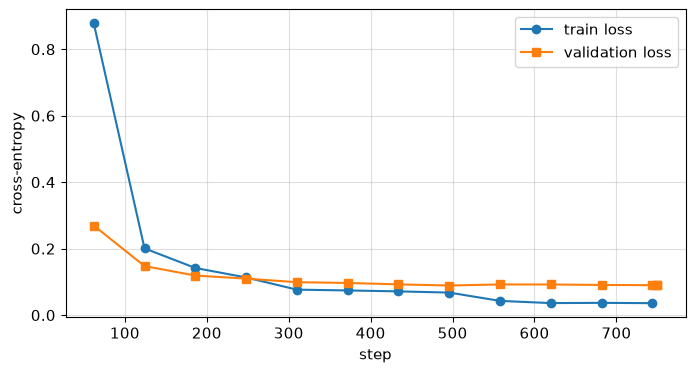

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized["train"], tokenized["validation"])
RUN_TIMES["train_main_sec"] = train_seconds
train_curve = [
    (
        h["step"],
        h["loss"],
    )
    for h in history
    if "loss" in h
]
eval_curve = [
    (
        h["step"],
        h["eval_loss"],
    )
    for h in history
    if "eval_loss" in h
]
assert (
    len(train_curve) >= 2 and len(eval_curve) >= 2
), "логируйте train и eval loss по ходу обучения"
print(
    f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)'
)

plt.figure(
    figsize=(
        8,
        4,
    )
)
plt.plot(*zip(*train_curve), "o-", label="train loss")
plt.plot(*zip(*eval_curve), "s-", label="validation loss")
plt.xlabel("step")
plt.ylabel("cross-entropy")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Для маленького энкодера выбран LR=2e-4; batch size=32 ограничивает память, три эпохи дают несколько проходов по выборке. Warmup 10% смягчает начало обучения случайной головы, weight decay=0.01 регуляризует веса; fp16 включается только на CUDA, на MPS используется float32. Train и validation loss записываются примерно 12 раз за обучение и в конце. Выводы о переобучении и достаточности эпох делаются по полученным кривым; время включает обучение и промежуточные оценки, устройство напечатано выше.

**Результат прогона:** За 86.2 с на MPS train loss изменился от 0.8783 до 0.0359; validation loss — от 0.2694 до 0.0901, минимум 0.0891. Записано 12 train- и 14 validation-точек. Заметного роста validation loss к концу нет; необходимость дополнительных эпох надо проверять отдельным экспериментом.

Начиная примерно со второй эпохи validation loss выходит на плато около 0.09, тогда как train loss падает до 0.036. Это показывает растущий разрыв между обучением и проверкой; следующим экспериментом выбрал бы раннюю остановку около второй эпохи по validation, а не просто увеличение числа эпох. Для совместимости с MPS используется attention в режиме eager; он одинаков у основного эксперимента и абляции.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    correct = predicted = actual = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        if len(gold_tags) != len(pred_tags):
            raise ValueError("Длины последовательностей не совпадают")
        for expected, obtained in zip(gold_tags, pred_tags, strict=True):
            actual += expected != "O"
            predicted += obtained != "O"
            correct += expected == obtained and expected != "O"
    denominator = actual + predicted
    return 2.0 * correct / denominator if denominator else 0.0

In [25]:
g, p = [
    [
        "B-PER",
        "I-PER",
        "O",
        "B-LOC",
    ],
], [
    [
        "B-PER",
        "O",
        "O",
        "B-LOC",
    ],
]
assert abs(token_f1(g, p) - 0.8) < 1e-9
assert abs(f1_score(g, p) - 0.5) < 1e-9
assert (
    token_f1(
        [
            [
                "O",
                "O",
            ],
        ],
        [
            [
                "O",
                "O",
            ],
        ],
    )
    == 0.0
    and token_f1(g, g) == 1.0
)


def evaluate_predictions(gold_tags, pred_tags):
    scores = entity_scores(gold_tags, pred_tags)
    report = classification_report(gold_tags, pred_tags, output_dict=True, zero_division=0)
    for entry in report.values():
        if isinstance(entry, dict) and "support" in entry:
            entry["support"] = int(entry["support"])
    scores["token_f1"] = token_f1(gold_tags, pred_tags)
    scores["per_type"] = {
        kind: report.get(
            kind,
            {
                "precision": 0.0,
                "recall": 0.0,
                "f1-score": 0.0,
                "support": 0,
            },
        )
        for kind in ENTITY_TYPES
    }
    return scores


val_pred = predict_word_tags(model, val_tokens)
validation_metrics = evaluate_predictions(val_gold, val_pred)
test_tokens = [
    list(words) for words in data["test"]["tokens"]
]
test_gold = [
    [
        LABEL_NAMES[i] for i in tags
    ] for tags in data["test"]["ner_tags"]
]
test_pred = predict_word_tags(model, test_tokens)
final = evaluate_predictions(test_gold, test_pred)
for split, gold_tags, pred_tags, scores in [
    (
        "validation",
        val_gold,
        val_pred,
        validation_metrics,
    ),
    (
        "test",
        test_gold,
        test_pred,
        final,
    ),
]:
    print(split)
    print(classification_report(gold_tags, pred_tags, digits=4, zero_division=0))
    print(json.dumps(scores, ensure_ascii=False, indent=2))

validation


              precision    recall  f1-score   support

         LOC     0.8650    0.8951    0.8798      1525
        MISC     0.5805    0.6334    0.6058       461
         ORG     0.6151    0.6509    0.6325       464
         PER     0.7969    0.8421    0.8189       741

   micro avg     0.7699    0.8095    0.7892      3191
   macro avg     0.7144    0.7554    0.7342      3191
weighted avg     0.7718    0.8095    0.7901      3191

{
  "f1_micro": 0.7891842346471127,
  "f1_macro": 0.7342403118490236,
  "precision": 0.7698956780923994,
  "recall": 0.8094641178314008,
  "token_f1": 0.8164182635438846,
  "per_type": {
    "LOC": {
      "precision": 0.8650190114068441,
      "recall": 0.8950819672131147,
      "f1-score": 0.8797937479858201,
      "support": 1525
    },
    "MISC": {
      "precision": 0.5805168986083499,
      "recall": 0.6334056399132321,
      "f1-score": 0.6058091286307054,
      "support": 461
    },
    "ORG": {
      "precision": 0.615071283095723,
      "recall": 0

              precision    recall  f1-score   support

         LOC     0.8727    0.8978    0.8851      1566
        MISC     0.6300    0.6429    0.6364       490
         ORG     0.6027    0.6806    0.6393       526
         PER     0.7709    0.8583    0.8122       635

   micro avg     0.7691    0.8157    0.7917      3217
   macro avg     0.7191    0.7699    0.7432      3217
weighted avg     0.7715    0.8157    0.7926      3217

{
  "f1_micro": 0.791672952179816,
  "f1_macro": 0.7432454144010243,
  "precision": 0.7690504103165299,
  "recall": 0.8156667702828723,
  "token_f1": 0.8160550458715596,
  "per_type": {
    "LOC": {
      "precision": 0.8727498448168839,
      "recall": 0.8978288633461047,
      "f1-score": 0.8851117406358199,
      "support": 1566
    },
    "MISC": {
      "precision": 0.63,
      "recall": 0.6428571428571429,
      "f1-score": 0.6363636363636364,
      "support": 490
    },
    "ORG": {
      "precision": 0.6026936026936027,
      "recall": 0.6806083650190

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Entity-F1 требует точного совпадения границ и типа, а token-F1 частично засчитывает правильно найденные слова в неполной сущности. Micro агрегирует все сущности и сильнее зависит от частых типов; macro усредняет F1 типов с одинаковым весом. Отчет выше позволяет сопоставить худший тип с его support и длинами сущностей из раздела 2.1, но одной частоты недостаточно для доказательства причины ошибки. Для извлечения имен целиком пользователю ближе F1 по сущностям; токенный F1 полезен как вспомогательная диагностика.

**Результат прогона:** На test micro-F1=0.7917, macro-F1=0.7432, token-F1=0.8161; разность token − entity равна +0.0244. Хуже всего MISC: F1=0.6364, support=490, средняя длина спана 1.71 слова. На validation micro-F1=0.7892. Более низкий macro-F1 показывает, что типы распознаются неравномерно: частые типы поднимают micro сильнее.

MISC объединяет разнородные сущности, например названия произведений и отдельные прилагательные, поэтому его границы и контексты менее однородны, чем у LOC. Это гипотеза по устройству класса и примерам, а не доказанная причинная связь: ORG в train встречается еще реже, но его F1 немного выше.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = [
    "correct",
    "boundary",
    "type",
    "missed",
    "spurious",
]


def categorize_errors(gold_spans, pred_spans):
    result = []
    for gold in gold_spans:
        overlaps = [
            pred for pred in pred_spans if max(gold[0], pred[0]) < min(gold[1], pred[1])
        ]
        exact = [
            pred for pred in overlaps if tuple(pred) == tuple(gold)
        ]
        same_type = [
            pred for pred in overlaps if pred[2] == gold[2]
        ]
        if exact:
            result.append(
                (
                    "correct",
                    gold,
                    exact[0],
                )
            )
        elif same_type:
            best = max(
                same_type, key=lambda pred: min(gold[1], pred[1]) - max(gold[0], pred[0])
            )
            result.append(
                (
                    "boundary",
                    gold,
                    best,
                )
            )
        elif overlaps:
            best = max(
                overlaps, key=lambda pred: min(gold[1], pred[1]) - max(gold[0], pred[0])
            )
            result.append(
                (
                    "type",
                    gold,
                    best,
                )
            )
        else:
            result.append(
                (
                    "missed",
                    gold,
                    None,
                )
            )
    for pred in pred_spans:
        if not any(max(gold[0], pred[0]) < min(gold[1], pred[1]) for gold in gold_spans):
            result.append(
                (
                    "spurious",
                    None,
                    pred,
                )
            )
    return result

In [27]:
gold = [
    (
        0,
        2,
        "PER",
    ),
    (
        4,
        5,
        "LOC",
    ),
    (
        7,
        9,
        "ORG",
    ),
    (
        11,
        12,
        "PER",
    ),
]
pred = [
    (
        0,
        2,
        "PER",
    ),
    (
        4,
        6,
        "LOC",
    ),
    (
        7,
        9,
        "LOC",
    ),
    (
        13,
        14,
        "ORG",
    ),
]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {
    "correct": 1,
    "boundary": 1,
    "type": 1,
    "missed": 1,
    "spurious": 1,
}
assert (
    "type",
    (
        7,
        9,
        "ORG",
    ),
    (
        7,
        9,
        "LOC",
    ),
) in res and (
    "spurious",
    None,
    (
        13,
        14,
        "ORG",
    ),
) in res
assert (
    "boundary",
    (
        4,
        5,
        "LOC",
    ),
    (
        4,
        6,
        "LOC",
    ),
) in res and (
    "missed",
    (
        11,
        12,
        "PER",
    ),
    None,
) in res
assert categorize_errors([], []) == [] and categorize_errors(
    [],
    [
        (
            0,
            1,
            "PER",
        ),
    ],
) == [
    (
        "spurious",
        None,
        (
            0,
            1,
            "PER",
        ),
    ),
]
assert [
    c
    for c, _, _ in categorize_errors(
        [
            (
                0,
                3,
                "LOC",
            ),
        ],
        [
            (
                1,
                2,
                "PER",
            ),
            (
                2,
                3,
                "LOC",
            ),
        ],
    )
] == [
    "boundary",
]
assert [
    c
    for c, _, _ in categorize_errors(
        [
            (
                0,
                2,
                "LOC",
            ),
            (
                2,
                4,
                "LOC",
            ),
        ],
        [
            (
                0,
                4,
                "LOC",
            ),
        ],
    )
] == [
    "boundary",
    "boundary",
]
assert sorted(
    c
    for c, _, _ in categorize_errors(
        [
            (
                0,
                2,
                "PER",
            ),
        ],
        [
            (
                2,
                3,
                "PER",
            ),
        ],
    )
) == [
    "missed",
    "spurious",
]

error_counts = collections.Counter()
error_examples = collections.defaultdict(list)
for words, gold_tags, pred_tags in zip(val_tokens, val_gold, val_pred, strict=True):
    categorized = categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags))
    for category, gold_span, pred_span in categorized:
        error_counts[category] += 1
        if category != "correct" and len(error_examples[category]) < 3:
            error_examples[category].append(
                {
                    "sentence": " ".join(words),
                    "gold": gold_span,
                    "pred": pred_span,
                    "gold_text": (
                        " ".join(words[gold_span[0] : gold_span[1]]) if gold_span else None
                    ),
                    "pred_text": (
                        " ".join(words[pred_span[0] : pred_span[1]]) if pred_span else None
                    ),
                }
            )
errors = {
    category: error_counts[category] for category in ERROR_CATEGORIES
}
error_total = sum(count for category, count in errors.items() if category != "correct")
error_shares = {
    category: count / error_total if error_total else 0.0
    for category, count in errors.items()
    if category != "correct"
}
print("Категории:", errors)
print("Доли среди ошибок:", error_shares)
for category, examples in error_examples.items():
    for example in examples:
        print(category, json.dumps(example, ensure_ascii=False))
assert sum(len(examples) for examples in error_examples.values()) >= 5

Категории: {'correct': 2583, 'boundary': 191, 'type': 329, 'missed': 88, 'spurious': 167}
Доли среди ошибок: {'boundary': 0.24645161290322581, 'type': 0.42451612903225805, 'missed': 0.1135483870967742, 'spurious': 0.21548387096774194}
boundary {"sentence": "Брокхауз стал профессором в университете Мак-Мастера в Канаде , где и оставался до пенсии в 1984 г .", "gold": [4, 6, "LOC"], "pred": [5, 6, "LOC"], "gold_text": "университете Мак-Мастера", "pred_text": "Мак-Мастера"}
boundary {"sentence": "Хотя ранее сообщалось , что к футболисту проявлял пристальный интерес московский ЦСКА .", "gold": [10, 12, "ORG"], "pred": [11, 12, "ORG"], "gold_text": "московский ЦСКА", "pred_text": "ЦСКА"}
boundary {"sentence": "Исполняется песня « Dance in the Dark » .", "gold": [3, 7, "MISC"], "pred": [3, 8, "MISC"], "gold_text": "Dance in the Dark", "pred_text": "Dance in the Dark »"}
spurious {"sentence": "Сведения , данные апостолами Лукой и Иоанном , носят относительно противоречивый характер .", "gold"

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Категории и доли ошибок приведены выше, примеры сгруппированы по границе, типу, пропуску и ложному срабатыванию. Это диагностический подсчет по контракту задания: одно предсказание может пересекать несколько истинных спанов, поэтому суммы категорий не заменяют precision/recall seqeval. В boundary проверяю включение служебных слов и частей имен; в type — неоднозначность организации и географического названия; в missed и spurious — неполноту автоматической разметки. Ошибку разметки нельзя объявить доказанной только из несогласия модели: для этого нужен ручной аудит с инструкцией аннотации.

**Результат прогона:** Чаще всего встречается type: 329 случаев, 42.5% диагностических ошибок. Для уменьшения путаницы типов собрал бы контекстные примеры ORG/LOC/MISC и проверил согласованность инструкции разметки.

Ручной разбор примеров: «московский ЦСКА» → «ЦСКА» — пропущен модификатор границы; в «Dance in the Dark» модель добавила закрывающую кавычку. «Сибирью» в контексте контракта футболиста обозначает клуб (ORG), но модель выбрала LOC; Hydro-Québec также перепутан с LOC. Слово «апостолами» ошибочно получило PER, хотя это обычное нарицательное существительное. Пропуски «Мария Неменко-Бабковская» и «Александра Охитина» находятся в хвосте длинного предложения: лимит входа делает такие ошибки ожидаемыми.

Есть кандидаты на ошибки silver-разметки: PER у «Содора» выглядит сомнительно по контексту «резиденция епископа Содора», где вероятнее географическое название; «якутское областное народное управление» похоже на пропущенное в эталоне название организации. Разметка также непоследовательна с кавычками: у `Сибирью »` закрывающая кавычка попала в gold, у «Dance in the Dark» — нет. Это основания для ручной перепроверки, а не для автоматического исправления эталона по предсказанию модели.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = "freeze"
main_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
model.cpu()
if device.type == "mps":
    torch.mps.empty_cache()
set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(
    frozen_model,
    tokenized["train"],
    tokenized["validation"],
    freeze_encoder=True,
    out_dir="runs/freeze",
)
frozen_pred = predict_word_tags(frozen_model, val_tokens)
frozen_scores = evaluate_predictions(val_gold, frozen_pred)
ablation = {
    "setting": ABLATION,
    "evaluation_split": "validation",
    "full": {
        "metrics": validation_metrics,
        "seconds": train_seconds,
        "trainable_params": main_trainable,
    },
    "freeze": {
        "metrics": frozen_scores,
        "seconds": frozen_seconds,
        "trainable_params": sum(
            p.numel() for p in frozen_model.parameters() if p.requires_grad
        ),
    },
    "delta_f1": frozen_scores["f1_micro"] - validation_metrics["f1_micro"],
}
RUN_TIMES["train_freeze_sec"] = frozen_seconds
print(json.dumps(ablation, ensure_ascii=False, indent=2))
frozen_model.cpu()
del frozen_model
model.to(device)

{'loss': '1.904', 'grad_norm': '4.392', 'learning_rate': '0.0001627', 'epoch': '0.248'}


{'eval_loss': '1.523', 'eval_runtime': '1.488', 'eval_samples_per_second': '1344', 'eval_steps_per_second': '42.34', 'epoch': '0.248'}


{'loss': '1.047', 'grad_norm': '1.84', 'learning_rate': '0.0001858', 'epoch': '0.496'}


{'eval_loss': '0.6816', 'eval_runtime': '1.533', 'eval_samples_per_second': '1305', 'eval_steps_per_second': '41.1', 'epoch': '0.496'}


{'loss': '0.537', 'grad_norm': '0.5666', 'learning_rate': '0.0001674', 'epoch': '0.744'}


{'eval_loss': '0.4539', 'eval_runtime': '1.512', 'eval_samples_per_second': '1323', 'eval_steps_per_second': '41.67', 'epoch': '0.744'}


... (18 outputs left out)

{'eval_loss': '0.2936', 'eval_runtime': '1.547', 'eval_samples_per_second': '1293', 'eval_steps_per_second': '40.73', 'epoch': '3'}
{'train_runtime': '42.01', 'train_samples_per_second': '571.3', 'train_steps_per_second': '17.85', 'train_loss': '0.5373', 'epoch': '3'}


{'eval_loss': '0.2936', 'eval_runtime': '1.528', 'eval_samples_per_second': '1309', 'eval_steps_per_second': '41.24', 'epoch': '3'}


{
  "setting": "freeze",
  "evaluation_split": "validation",
  "full": {
    "metrics": {
      "f1_micro": 0.7891842346471127,
      "f1_macro": 0.7342403118490236,
      "precision": 0.7698956780923994,
      "recall": 0.8094641178314008,
      "token_f1": 0.8164182635438846,
      "per_type": {
        "LOC": {
          "precision": 0.8650190114068441,
          "recall": 0.8950819672131147,
          "f1-score": 0.8797937479858201,
          "support": 1525
        },
        "MISC": {
          "precision": 0.5805168986083499,
          "recall": 0.6334056399132321,
          "f1-score": 0.6058091286307054,
          "support": 461
        },
        "ORG": {
          "precision": 0.615071283095723,
          "recall": 0.6508620689655172,
          "f1-score": 0.6324607329842933,
          "support": 464
        },
        "PER": {
          "precision": 0.7969348659003831,
          "recall": 0.8421052631578947,
          "f1-score": 0.8188976377952755,
          "support": 741

BertForTokenClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(83828, 312, padding_idx=0)
      (position_embeddings): Embedding(2048, 312)
      (token_type_embeddings): Embedding(2, 312)
      (LayerNorm): LayerNorm((312,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-2): 3 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=312, out_features=312, bias=True)
              (key): Linear(in_features=312, out_features=312, bias=True)
              (value): Linear(in_features=312, out_features=312, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=312, out_features=312, bias=True)
              (LayerNorm): LayerNorm((312,), eps

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Сравниваются одинаковые train и validation, seed, начальные веса энкодера и головы, число эпох, LR и расписание оценок; отличается только requires_grad энкодера. В ablation приведены F1 на validation, разность freeze − full, время и число обучаемых параметров. Заморозка сокращает обратный проход, но лишает модель адаптации контекстных признаков к NER; голова должна разделить классы на фиксированных представлениях. Один seed и одинаковый LR дают ограниченный вывод: далее нужны несколько seed и отдельный подбор LR головы на validation. Test для выбора варианта не используется.

**Результат прогона:** Full: F1=0.7892, 86.2 с, 29,098,929 обучаемых параметров; freeze: F1=0.4368, 43.7 с, 2,817 параметров. Разность F1=-0.3524, отношение времени full/freeze=1.97. Адаптация энкодера улучшила качество при одинаковом бюджете эпох.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** На validation словарный бейзлайн получил entity-F1=0.4070, случайная голова — 0.0294, полное дообучение — 0.7892. На отложенном test достигнуты micro-F1=0.7917, macro-F1=0.7432 и token-F1=0.8161, поэтому точные границы остаются важной частью оценки. Худший тип — MISC с F1=0.6364; его ошибки требуют проверки частоты, контекста и разметки, а не объяснения только редкостью. Основное обучение на MPS заняло 86.2 с за три эпохи на 8000 предложений, а заморозка дала validation-F1=0.4368 за 43.7 с. Самая частая диагностическая ошибка — type (42.5%); в train потеряно 96 слов из-за токенизации или лимита длины. Ограничения — один seed, небольшая фиксированная выборка Wikipedia и автоматическая silver-разметка, поэтому результат нельзя без проверки переносить на новости и соцсети. Следующим шагом я бы проверил несколько seed, увеличил длину входа и вручную перепроверил трудные примеры самой частой категории, сохранив test для окончательной оценки.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {
            str(k): json_ready(v) for k, v in value.items()
        }
    if isinstance(
        value,
        (
            tuple,
            list,
        ),
    ):
        return [
            json_ready(v) for v in value
        ]
    if isinstance(
        value,
        (
            float,
            np.floating,
        ),
    ):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track="nlp",
    model=MODEL_ID,
    revision=REVISION,
    dataset=f"{DATASET_ID}/{DATASET_CONFIG}" if DATASET_CONFIG else str(DATASET_ID),
    classes=ENTITY_TYPES,
    n_train=len(data["train"]),
    n_val=len(data["validation"]),
    n_test=len(data["test"]),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline,
    final=final,
    ablation=ablation,
    errors=errors,
    device=DEVICE_NAME,
    train_time_sec=RUN_TIMES.get("train_main_sec"),
    fast_mode=FAST_MODE,
)
for key in [
    "f1_micro",
    "f1_macro",
    "precision",
    "recall",
    "token_f1",
    "per_type",
]:
    assert key in final, f"в final нет {key}"
(ARTIFACTS / "metrics.json").write_text(
    json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding="utf-8"
)
print(
    json.dumps(
        json_ready(
            {
                k: v
                for k, v in metrics.items()
                if k
                not in (
                    "final",
                    "baseline",
                )
            }
        ),
        ensure_ascii=False,
    )[:600]
)
print("final F1 micro", round(final["f1_micro"], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 8000, "n_val": 2000, "n_test": 2000, "params_total": 29098929, "ablation": {"setting": "freeze", "evaluation_split": "validation", "full": {"metrics": {"f1_micro": 0.7891842346471127, "f1_macro": 0.7342403118490236, "precision": 0.7698956780923994, "recall": 0.8094641178314008, "token_f1": 0.8164182635438846, "per_type": {"LOC": {"precision": 0.8650190114068441, "recall": 0.8950819672131147, "f1-s
final F1 micro 0.7917


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if "6.1" in BONUS_TASKS:

    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус 6.1 не выполнялся; новых предложений не размечал.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if "6.2" in BONUS_TASKS:

    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Бонус 6.2 не выполнялся; в абляции сравнивается одна архитектура с разными режимами обучения.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if "6.3" in BONUS_TASKS:
    shifted_metrics = {}
    for name, transform in [
        (
            "lowercase",
            str.lower,
        ),
        (
            "uppercase",
            str.upper,
        ),
    ]:
        shifted_tokens = [
            [
                transform(word) for word in words
            ] for words in val_tokens
        ]
        shifted_pred = predict_word_tags(model, shifted_tokens)
        scores = entity_scores(val_gold, shifted_pred)
        scores["delta_f1"] = scores["f1_micro"] - validation_metrics["f1_micro"]
        shifted_metrics[name] = scores
    print(json.dumps(shifted_metrics, ensure_ascii=False, indent=2))

{
  "lowercase": {
    "f1_micro": 0.16786355475763015,
    "f1_macro": 0.15107053553281832,
    "precision": 0.2956521739130435,
    "recall": 0.11720463804450015,
    "delta_f1": -0.6213206798894826
  },
  "uppercase": {
    "f1_micro": 0.030063742745694986,
    "f1_macro": 0.02693447452160714,
    "precision": 0.021584699453551914,
    "recall": 0.04951425885302413,
    "delta_f1": -0.7591204919014177
  }
}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Оба преобразования сохраняют количество слов и их индексы, поэтому BIO-разметка не меняется; сравнение проводится на том же validation. Регистр — полезный признак имени собственного, а cased-токенизатор может иначе сегментировать lower/uppercase-формы. В таблице выше приведены F1 и изменение относительно исходного текста; по ним выбирается более разрушительный сдвиг. Такой тест измеряет чувствительность к конкретному изменению записи, а не перенос на произвольный новый домен.

**Результат прогона:** lowercase: F1=0.1679, изменение -0.6213; uppercase: F1=0.0301, изменение -0.7591. Более низкий F1 у uppercase; исходный F1=0.7892.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if "6.4" in BONUS_TASKS:

    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Бонус 6.4 не выполнялся; время прямого прохода в разделе 1.2 не является сравнением оптимизаций.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean {"threshold": 0.7000000000000001, "f1_micro": 0.8007270323859882, "f1_macro": 0.742925414393162, "precision": 0.846906675987417, "recall": 0.7593230962080852} gain 0.011542797738875454


min {"threshold": 0.6000000000000001, "f1_micro": 0.7984445884640311, "f1_macro": 0.7396046624781748, "precision": 0.8265682656826568, "recall": 0.7721717329990598} gain 0.009260353816918365


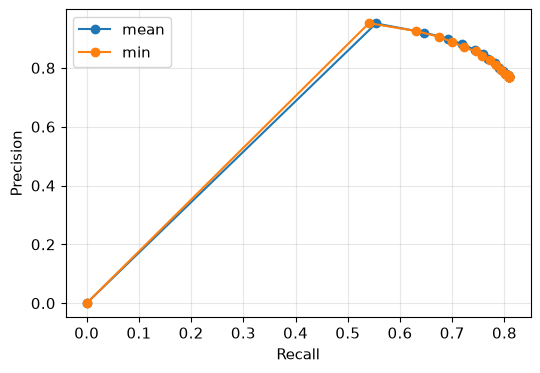

In [34]:
if "6.5" in BONUS_TASKS:
    threshold_tags, threshold_probs = predict_word_tags(model, val_tokens, return_probs=True)

    def filter_spans(tags_list, probs_list, threshold, aggregation):
        filtered = []
        for tags, probs in zip(tags_list, probs_list, strict=True):
            kept = []
            for start, end, kind in bio_to_spans(tags):
                confidence = (
                    float(np.mean(probs[start:end]))
                    if aggregation == "mean"
                    else min(probs[start:end])
                )
                if confidence >= threshold:
                    kept.append(
                        (
                            start,
                            end,
                            kind,
                        )
                    )
            filtered.append(spans_to_bio(kept, len(tags)))
        return filtered

    threshold_results = {}
    plt.figure(
        figsize=(
            6,
            4,
        )
    )
    for aggregation in [
        "mean",
        "min",
    ]:
        rows = []
        for threshold in np.linspace(0.0, 1.0, 21):
            filtered = filter_spans(
                threshold_tags, threshold_probs, float(threshold), aggregation
            )
            scores = entity_scores(val_gold, filtered)
            rows.append(
                {
                    "threshold": float(threshold),
                    **scores,
                }
            )
        best = max(
            rows,
            key=lambda row: (
                row["f1_micro"],
                -row["threshold"],
            ),
        )
        threshold_results[aggregation] = {
            "best": best,
            "gain_f1": best["f1_micro"] - rows[0]["f1_micro"],
            "curve": rows,
        }
        assert all(
            later["recall"] <= earlier["recall"] + 1e-12
            for earlier, later in zip(rows, rows[1:])
        )
        plt.plot(
            [
                row["recall"] for row in rows
            ],
            [
                row["precision"] for row in rows
            ],
            "o-",
            label=aggregation,
        )
        print(aggregation, json.dumps(best), "gain", threshold_results[aggregation]["gain_f1"])
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Порог подбирается только на validation по сетке с шагом 0.05; при равном F1 выбирается меньший порог. Средняя уверенность сглаживает отдельное неуверенное слово, минимальная отклоняет весь спан из-за одного такого слова и потому строже для длинных имен. Фильтрация удаляет готовые спаны, но не добавляет новых правильных сущностей: recall может только сохраняться или уменьшаться. Лучшие пороги и прирост относительно нуля напечатаны выше; это результат подбора на validation, а не доказательство такого же улучшения на test.

**Результат прогона:** mean: лучший порог 0.70, F1=0.8007, прирост +0.0115; min: лучший порог 0.60, F1=0.7984, прирост +0.0093. Прирост указан в абсолютных долях F1, а не процентах.

In [35]:
analysis = {
    "source_sizes": source_sizes,
    "dataset_revision": DATASET_REVISION,
    "dataset_stats": dataset_stats,
    "roundtrip": roundtrip_stats,
    "architecture": blocks,
    "demo_input_shape": list(out.logits.shape[:2]),
    "hidden_size": cfg.hidden_size,
    "truncation": {
        "sentences_at_limit": n_truncated,
        "lost_words": n_lost_words,
        "fully_checked": n_checked,
    },
    "validation": validation_metrics,
    "error_shares": error_shares,
    "error_examples": dict(error_examples),
    "history": history,
    "frozen_history": frozen_history,
    "shift": shifted_metrics if "6.3" in BONUS_TASKS else None,
    "thresholds": threshold_results if "6.5" in BONUS_TASKS else None,
    "versions": {
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "datasets": datasets.__version__,
    },
}
(ARTIFACTS / "analysis.json").write_text(
    json.dumps(json_ready(analysis), ensure_ascii=False, indent=2),
    encoding="utf-8",
)
metrics["dataset_revision"] = DATASET_REVISION
metrics["seed"] = SEED
metrics["bonus_tasks"] = sorted(BONUS_TASKS)
metrics["validation"] = validation_metrics
metrics["versions"] = analysis["versions"]
(ARTIFACTS / "metrics.json").write_text(
    json.dumps(json_ready(metrics), ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("Сохранены artifacts/metrics.json и artifacts/analysis.json")

Сохранены artifacts/metrics.json и artifacts/analysis.json
